In [365]:
# multi class classification of FGL sources using tree categories
import numpy as np
import pandas as pd
from matplotlib import pyplot
from scipy.stats import binom
from astropy.io import fits
import os

from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_curve, roc_auc_score

import sys
if '../../lib/' not in sys.path:
    sys.path.append('../../lib/')
import dio3
import multi_fgl_utils as util
import plot_util as putil

In [366]:
if 1:
    import importlib
    importlib.reload(util);


In [367]:
lst = [1, 2, 3]
lst[-3]

1

In [368]:
def max_classes(cls, nsrc_dict=None, ncl=3):
    if len(cls) < ncl or nsrc_dict is None:
        return cls
    nmin = 0
    res = []    
    for cl in cls:
        if nsrc_dict[cl] > nmin:
            res.append(cl)
            if len(res) >= ncl:
                nmin = nsrc_dict[res[-ncl]]
    return res[-ncl:]

def list2label(lst, nsrc_dict=None, ncl=3, max_only=True):
    res = ''
    if max_only:
        lst_ = max_classes(lst, nsrc_dict=nsrc_dict, ncl=ncl)
    else:
        lst_ = lst
    for s in lst_:
        res += '%s ' % s
    if max_only and len(lst) > ncl:
        res += '+ '
    return res


def get_descr_str(llat_ROI, hlat_ROI, cdict={}, bmask=10, output_text=False):
    feature_mode = cdict.get('features', '')
    if output_text:
        res = cdict.get('cat_name', '4FGL-DR4')
        if feature_mode.find('Toby') > -1:
            res += ' Toby'
        if npar == 1:
            res += ' const prior'
        else:
            res += ' %s prior, %i params' % (mdl_func.__name__, npar)
        if llat_ROI:
            res += r', $|b| < %i^\circ$' % bmask
        if hlat_ROI:
            res += r', $|b| > %i^\circ$' % bmask
        return res
    res = cdict.get('case', '4FGL-DR4')
    if feature_mode.find('Toby') > -1:
        res += ' Toby'
    if llat_ROI:
        res += '_unas_below_b%i' % bmask
    if hlat_ROI:
        res += '_unas_above_b%i' % bmask
    return res



# load the cat tree
nmin = 60 # 15, 50, 100
low_lat = True
mask_TS = False
folder = '../../data_out/'
if 1:
    Eind = 1000
    xdf_fn = folder + 'xdf_fgl_Eind%iMeV.csv' % Eind
    #xdf_fn = folder + 'xdf_fgl.csv'
    class_clm = 'CLASS1'
else:
    xdf_fn = folder + 'xdf.csv'
    class_clm = 'class'
    
xdf0 = pd.read_csv(xdf_fn, index_col=0)
xdfnames = np.array([str(x).strip() for x in xdf0.index], dtype=str)
xdf = pd.DataFrame(index=xdfnames, data=xdf0.values, columns=xdf0.columns)

#out_fn = folder_out + 'cat_tree_nmin%i.yaml' % nmin
#tree_cat_fn = folder_out + 'tree_cat_nmin%i.yaml' % nmin
feature_mode = 'no coord features' # 'all features', 'no coord features'


tree_cat_fn = folder + 'tree_cat_nmin60_RF_no_bcu_spp.yaml'
tree_cat_dict = dio3.loaddict(tree_cat_fn)
all_features = [name for name in xdf.columns if name != class_clm]
if feature_mode == 'no coord features':
    features = [feat for feat in all_features if feat.find('GL') == -1]
else:
    features = all_features
    
ns = len(xdf)

assoc_classes = []
for cls in tree_cat_dict.values():
    assoc_classes.extend(cls)
nsrc_dict = {cl:np.sum(xdf[class_clm] == cl) for cl in assoc_classes}

alg = 'RF'
pars_dict = {'RF':{'max_depth': 15, 'n_estimators': 50,},
             'NN':{'activation': 'tanh', 'hidden_layer_sizes': (20, 10,),},
             'BDT':{'max_depth': 15},
             'LR':{'max_iter':1000},
            }
test_frac = .3
max_depth = util.max_node_length(tree_cat_dict.keys()) - 1
#descr_str = '%s_max_depth%i_nmin%i' % (alg, max_depth, nmin)
descr_str = '5class_RF_nmin60_no_bcu_spp_no_coord_features'
if not mask_TS:
    descr_str += '_no_TS_mask'

save_plots = 1
save_png = 0
plots_folder = '../../plots/SGU/%s/' % descr_str
if not os.path.isdir(plots_folder):
    os.makedirs(plots_folder)


In [408]:
script_fn = 'fermi_multiclass/notebooks/cov_shift/prior_shift_model.ipynb'
fig_meta = {'Author': 'Dmitry Malyshev', 'Subject': script_fn}

kde_method = 'GMM' # 'GMM', 'KDE_gauss'
data_case = None

# select the catalog and the case
cat_name = '4FGL-DR4' # '4FGL-DR3'
if cat_name == '4FGL-DR4':
    #baseline_case = '4FGL-DR4_GMM_RF_no_coord' # '4FGL-DR4_GMM_RF', '4FGL-DR4_2class_RF'
    #case = '4FGL-DR4_GMM_RF_no_coord'
    baseline_case = '4FGL-DR4_GMM_RF_no_coord_no_bcu_spp'
    case = '4FGL-DR4_GMM_RF_no_coord_no_bcu_spp' # '4FGL-DR4_GMM_RF_no_prune'
    #case = '4FGL-DR4_GMM_RF_no_coord_no_bcu_spp_4class' # analysis for KDE paper
    #data_case = 'Toby'
    #baseline_case = '4FGL-DR4_2class_RF' # '4FGL-DR4_GMM_RF', '4FGL-DR4_2class_RF'
    #case = '4FGL-DR4_2class_RF_no_coord_no_bcu_spp'
    #case = '4FGL-DR4_2class_RF_no_coord'
    #baseline_case = '4FGL-DR4_GMM_RF_no_coord'
    #case = '4FGL-DR4_GMM_RF_no_coord'
if cat_name == '4FGL-DR3':
    #baseline_case = '4FGL-DR3_GMM_RF_no_coord_no_bcu_spp'
    #case = '4FGL-DR3_GMM_RF_no_coord_no_bcu_spp'
    baseline_case = '4FGL-DR3_2class_RF'
    case = '4FGL-DR3_2class_RF_no_coord_no_bcu_spp'

    
baseline = (case == baseline_case)
root_folder = '../../'
config_folder = root_folder + 'config/'

# generic inputs
cdict = util.get_config_dict(#cat_name=cat_name, 
                             baseline_case=baseline_case, 
                             #baseline_fn=baseline_fn,
                             #cases_fn=cases_fn,
                             case=case, 
                             folder=config_folder)

cdict['case'] = case
cdict['root_folder'] = root_folder
folder_in = cdict['root_folder'] + cdict.get('folder_in', 'data_in/')
folder_out = cdict['root_folder'] + cdict.get('folder_out', 'data_out/')
folder = folder_out
Eind = int(cdict.get('Eind', 1000))
class_name = cdict.get('class_name', 'CLASS1')

assoc_sources = cdict.get('assoc_sources', 'all_assoc')
sep_model = cdict.get('sep_model', 'GMM')
max_depth = int(cdict.get('max_depth', 5))
feature_mode = cdict.get('features', 'all_features')
feature_mode = 'no_coord_features' # 'spec_features', 'spec_features_Epeak', 'Tobys_features'


alg = cdict.get('class_alg', 'RF')

# input data
tree_cat_fn = util.get_tree_cat_fn(cdict)
tree_cat_dict = dio3.loaddict(tree_cat_fn)
if util.exist_internal(tree_cat_dict):
    util.remove_internal(tree_cat_dict)
    

cat_tree = list(tree_cat_dict.keys())

xdf_fn = util.get_xdf_fn(cdict)
xdf = pd.read_csv(xdf_fn, index_col=0)
ns = len(xdf)
ncomp = len(tree_cat_dict)
nsrc_dict = util.get_nsrc_dict(xdf)
nsrc_df = util.nsrc_dict2df(nsrc_dict)

all_features = [name for name in xdf.columns if name.find('CLASS') == -1]
if feature_mode == 'all_features':
    features = all_features
elif feature_mode == 'no_coord_features':
    features = [feat for feat in all_features if feat.find('GL') == -1]
elif feature_mode == 'spec_features':
    features = ['log10(Energy_Flux100)', 'LP_index1000MeV', 'LP_beta',]
elif feature_mode == 'beta_Epeak_only':
    features = ['LP_beta', 'log10Epeak',]
elif feature_mode == 'spec_beta_Epeak':
    features = ['log10(Energy_Flux100)', 'LP_beta', 'log10Epeak',]
elif feature_mode == 'spec_features_Epeak':
    features = ['log10(Energy_Flux100)', 'LP_index1000MeV', 'log10Epeak', 'LP_beta',]
elif feature_mode.find('Toby') > -1:
    features = ['log10(Energy_Flux100)', 'LP_index1000MeV', 'd', 'diffuse']
if 'log10Epeak' in features:
    inds = xdf['LP_index1000MeV']
    beta = xdf['LP_beta']
    log10Epeak = 0.5 * (2. - inds) / beta
    #log10Epeak = np.maximum(-1.1, log10Epeak)
    #log10Epeak = np.minimum(2.1, log10Epeak)
    xdf['log10Epeak'] = log10Epeak

if 0:
    # add features from the catalog
    fn = util.get_cat_fn(cdict)
    cat_hdu = fits.open(fn)
    #cat_hdu[1].header
    ctab = cat_hdu[1].data 
    ns = len(ctab)
    fdict = {}
    fdict['LP_EPeak'] = np.log10(ctab['LP_EPeak'])
    snames = np.array([name.strip() for name in ctab['Source_Name']])
    cols = ['Signif_Avg', 'PL_Index', 'GLAT']
    plot_features = ['PL_Index', 'GLAT', 'GLON', 'LP_SigCurv', 'LP_index500MeV', 
                     'LP_index1000MeV', 'LP_index3000MeV']
    for feature in plot_features:
        if feature not in cols: 
            cols.append(feature)


    xdf_extra = pd.DataFrame(data=fdict, index=snames)

    extra_features = ['LP_EPeak']
    for feature in extra_features:
        xdf[feature] = xdf_extra.loc[xdf.index][feature]

hlat_ROI = 0
llat_ROI = 1
if hlat_ROI:
    bmask = 10
    hmask = np.abs(xdf['sin(GLAT)']) > np.sin(np.deg2rad(bmask)) # select high latitudes
    #xdf = xdf[hmask]
    ROI_name = 'High lat sources'
elif llat_ROI:
    bmask = 10
    hmask = np.abs(xdf['sin(GLAT)']) < np.sin(np.deg2rad(bmask)) # select low latitudes
    #xdf = xdf[hmask]
    ROI_name = 'Low lat sources'
else:
    hmask = True
    ROI_name = 'All sky'
    bmask = None

    
descr_str = get_descr_str(llat_ROI, hlat_ROI, cdict=cdict, bmask=bmask)
print(descr_str)
for key, cls in tree_cat_dict.items():
    mcl = max_classes(cls, nsrc_dict=nsrc_dict, ncl=1)[0]
    print('%s+: %s' % (mcl, cls))

4FGL-DR4_GMM_RF_no_coord_no_bcu_spp_unas_below_b10
bll+: ['agn', 'sey', 'bll', 'rdg', 'sbg']
fsrq+: ['nlsy1', 'ssrq', 'fsrq', 'css']
psr+: ['pwn', 'sfr', 'gc', 'snr', 'psr', 'hmb', 'nov']
msp+: ['lmb', 'bin', 'gal', 'msp', 'glc']


In [409]:
xdf.columns

Index(['sin(GLAT)', 'cos(GLON)', 'sin(GLON)', 'log10(Energy_Flux100)',
       'log10(Unc_Energy_Flux100)', 'log10(Signif_Avg)', 'LP_index1000MeV',
       'LP_beta', 'LP_SigCurv', 'log10(Variability_Index)', 'CLASS1'],
      dtype='object')

In [410]:
save_plots = 1
save_png = 1
plots_folder = '../../plots/SGU/%s/' % descr_str
if not os.path.isdir(plots_folder):
    os.makedirs(plots_folder)


folder_in = '../../data_in/'
#fn = folder_in + '4FGL-DR3_categories.csv'
#classes_df = pd.read_csv(fn)

fn = folder_in + 'gll_psc_v32.fit'
cat_hdu = fits.open(fn)
ctab = cat_hdu[1].data 
#ns = len(ctab)
cols = ['Signif_Avg', 'PL_Index', 'GLAT']
plot_features = ['PL_Index', 'GLAT', 'GLON', 'LP_SigCurv', 'LP_index500MeV', 
                 'LP_index1000MeV', 'LP_index3000MeV', 'LP_EPeak']
for feature in plot_features:
    if feature not in cols: 
        cols.append(feature)

names = np.array([str(x).strip() for x in ctab['Source_Name']], dtype=str)
df_extra = pd.DataFrame(index=names, columns=cols, data=0.)
#df_extra = pd.DataFrame(index=ctab['Source_Name'], columns=cols, data=0.)
for col in cols:
    if col in ctab.names:
        df_extra[col] = np.array(ctab[col], dtype=float)
    elif col in xdf.columns:
        df_extra[col] = xdf[col]
    elif col.find('LP_index') > -1:
        Eind = int(col.replace('LP_index', '').replace('MeV', ''))
        df_extra[col] = util.logpar_index_cat(Eind, ctab)

class_clm = 'CLASS1'
df_extra['TS'] = np.sum(ctab['Sqrt_TS_Band']**2, axis=1)
fgl_classes = np.array([cl.lower() for cl in ctab['CLASS1']])
fgl_classes[fgl_classes == ''] = 'unas'
df_extra[class_clm] = fgl_classes
#xdfnames = np.array([str(x).strip() for x in xdf0.index], dtype=str)
xdfnames = xdf.index
df_extra = df_extra.loc[xdfnames]

extra_features = ['LP_EPeak']
for feature in extra_features:
    xdf[feature] = df_extra.loc[xdf.index][feature]


In [411]:
df_extra.columns

Index(['Signif_Avg', 'PL_Index', 'GLAT', 'GLON', 'LP_SigCurv',
       'LP_index500MeV', 'LP_index1000MeV', 'LP_index3000MeV', 'LP_EPeak',
       'TS', 'CLASS1'],
      dtype='object')

In [412]:
check_SGUs = False
if check_SGUs:
    # check with SGU list from https://confluence.slac.stanford.edu/display/SCIGRPS/Bright+SGUs
    fn = folder_in + 'high_TS_SGUs.fits'
    sgu_hdu = fits.open(fn)
    stab = sgu_hdu[1].data 
    sgus = np.array([str(x).strip() for x in stab['NAME']], dtype=str)
    sgus_in = [x for x in sgus if x in df_extra.index]
    sgus_out = [x for x in sgus if x not in sgus_in]
    print(len(sgus_in), len(sgus_out) )

In [413]:
assoc_classes = []
for cls in tree_cat_dict.values():
    assoc_classes.extend(cls)
clf_mask_all = util.get_cl_mask(assoc_classes, xdf, cname=class_name)
if 1:
    unas_mask = (xdf[class_name] == 'unas')
else:
    unas_mask = ~clf_mask_all


In [414]:
# SGU conditions
# "unassociated  && 100<TS<500 && PL_Index> 2.4 && |b| <10°".
mask_TS = False
if llat_ROI or hlat_ROI:
    sgu_mask = hmask.copy()
else:
    sgu_mask = np.ones_like(df_extra['GLAT'], dtype=bool)
    
print('Total number of sources:', sum(sgu_mask))
if mask_TS:
    sgu_mask &= df_extra['TS'] < 500.
    print(sum(sgu_mask))
    sgu_mask &= df_extra['TS'] > 100.
    #sgu_mask &= df_extra['TS'] > 25
    print(sum(sgu_mask))

#sga_mask = sgu_mask & (xdf[class_clm] != 'unas')
sga_mask = sgu_mask & clf_mask_all
sgu_mask &= unas_mask
nsgu = sum(sgu_mask)
print('N SGU:', nsgu)
print('N SGA:', sum(sga_mask))
if 0:
    print(sum((xdf[class_clm] == 'bcu') & hmask))
    print(sum((xdf[class_clm] == 'spp') & hmask))
    print(sum((xdf[class_clm] == 'unk') & hmask))
    print(sum((xdf[class_clm] != 'unas') & hmask))

Total number of sources: 2122
N SGU: 1146
N SGA: 410


In [415]:
horiz_trees = util.get_horiz_trees(cat_tree)
max_depth = np.minimum(max_depth, len(horiz_trees))
#cat_forest = util.get_forest(max_depth=5, max_tree=cat_tree)
#print(len(cat_forest))

In [416]:
max_depth

2

In [417]:
# get a random cut
#ind = np.random.randint(len(cat_forest))
if 0:
    use_max = True
    if use_max:
        ind = -1
    else:
        ind = 50
    subtree = cat_forest[ind]
    cut_subtree = util.sub_tree2tree_cat_dict(subtree, cat_tree, tree_cat_dict)
else:
    subtree = horiz_trees[max_depth - 1]
    cut_subtree = util.sub_tree2tree_cat_dict(subtree, cat_tree, tree_cat_dict)
print(subtree)

['000', '001', '010', '011']


In [418]:
print('Max tree, %i leafs:' % len(tree_cat_dict))
for key, cls in tree_cat_dict.items():
    nsrc = np.sum([nsrc_dict[cl] for cl in cls])
    print(key, cls, nsrc)
print()
print('Subtree, %i leafs:' % len(cut_subtree))
for key, cls in cut_subtree.items():
    nsrc = np.sum([nsrc_dict[cl] for cl in cls])
    print(key, cls, nsrc)


Max tree, 4 leafs:
000 ['agn', 'sey', 'bll', 'rdg', 'sbg'] 1563
001 ['nlsy1', 'ssrq', 'fsrq', 'css'] 835
010 ['pwn', 'sfr', 'gc', 'snr', 'psr', 'hmb', 'nov'] 231
011 ['lmb', 'bin', 'gal', 'msp', 'glc'] 238

Subtree, 4 leafs:
000 ['agn', 'sey', 'bll', 'rdg', 'sbg'] 1563
001 ['nlsy1', 'ssrq', 'fsrq', 'css'] 835
010 ['pwn', 'sfr', 'gc', 'snr', 'psr', 'hmb', 'nov'] 231
011 ['lmb', 'bin', 'gal', 'msp', 'glc'] 238


In [419]:
ys = np.zeros(ns, dtype='<U6')
clf_mask = np.zeros(ns, dtype=bool)
for key, cls in cut_subtree.items():
    cls_mask = util.get_cl_mask(cls, xdf, cname=class_clm)
    ys[cls_mask] = key
    clf_mask[cls_mask] = True

In [420]:
X = xdf[features][clf_mask]
y = ys[clf_mask]


In [421]:
keys = list(cut_subtree.keys())
#prob_prec_test = np.zeros((nav, len(keys)))
#prob_recall_test = np.zeros((nav, len(keys)))
#nsrc_test = np.zeros((nav, len(keys)))

clf = util.get_classifier(alg, util.pars_dict[alg])
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=.3, random_state=0)
clf.fit(X_train, y_train)


RandomForestClassifier(max_depth=15, n_estimators=50)

In [422]:
Xsgu = xdf[features][sgu_mask]
ysgu = clf.predict_proba(Xsgu).T

In [423]:
clf.classes_

array(['000', '001', '010', '011'], dtype='<U6')

In [424]:
psum = [np.sum(ysgu[i]) for i in range(len(clf.classes_))]
psum_sorted = np.sort(psum)[::-1]
ind_sort = [psum.index(v) for v in psum_sorted]


In [425]:
ind_sort, psum_sorted, psum

([3, 2, 1, 0],
 array([414.80741982, 355.48090289, 192.17104274, 183.54063455]),
 [183.5406345521895,
  192.17104273506357,
  355.4809028941387,
  414.80741981860825])

save figure to file: ../../plots/SGU/4FGL-DR4_GMM_RF_no_coord_no_bcu_spp_unas_below_b10//mclass_SGU_class_p_hist_4FGL-DR4_GMM_RF_no_coord_no_bcu_spp_unas_below_b10.pdf


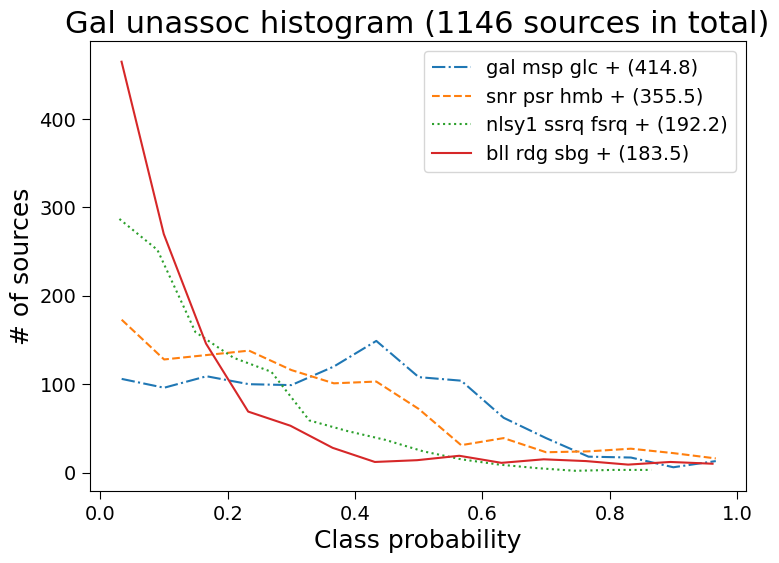

In [426]:
#bins = np.linspace(0, 1, 20)
putil.setup_figure_pars()
lss = ['-', ':', '--', '-.']
bins = 15
pyplot.figure()
for i in ind_sort:
#for i, cls in enumerate(clf.classes_):
    cls = clf.classes_[i]
    if np.sum(ysgu[i]) > 2.:
        y, xb = np.histogram(ysgu[i], bins=bins)
        xc = (xb[1:] + xb[:-1]) / 2.
        #label = list2label(cut_subtree[cls]) + '(%.1f)' % psum[i]
        label = list2label(cut_subtree[cls], nsrc_dict, ncl=3, max_only=True)\
                    + '(%.1f)' % psum[i]
        pyplot.plot(xc, y, ls=lss[i%len(lss)], label=label)

pyplot.legend()
#pyplot.ylim(0, 50)
pyplot.xlabel('Class probability')
pyplot.ylabel('# of sources')
pyplot.title('Gal unassoc histogram (%i sources in total)' % nsgu)


if save_plots:
    fn = '%s/mclass_SGU_class_p_hist_%s.pdf' % (plots_folder, descr_str)
    print('save figure to file: %s' % (fn))
    pyplot.savefig(fn)
    if save_png:
        fn = fn.replace('.pdf', '.png')
        pyplot.savefig(fn)


save figure to file: ../../plots/SGU/4FGL-DR4_GMM_RF_no_coord_no_bcu_spp_unas_below_b10//mclass_SGU_expected_4FGL-DR4_GMM_RF_no_coord_no_bcu_spp_unas_below_b10.pdf


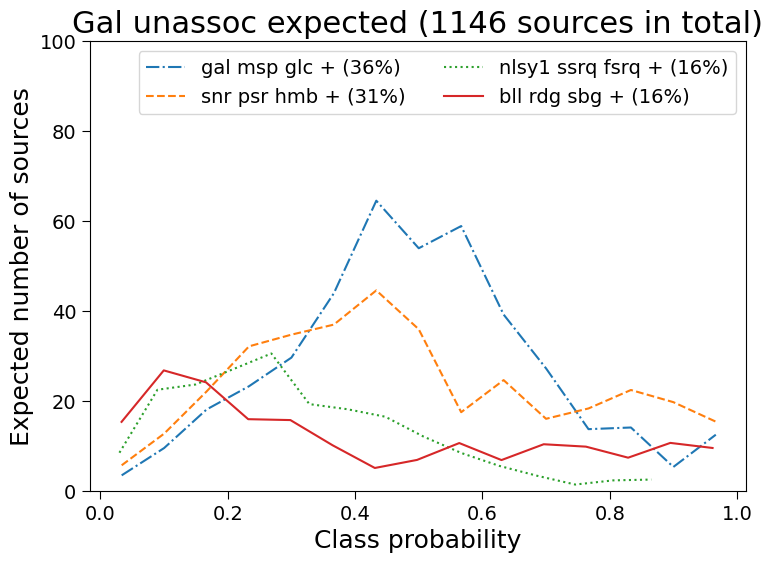

In [436]:
#bins = np.linspace(0, 1, 20)
putil.setup_figure_pars()
lss = ['-', ':', '--', '-.']
bins = 15
pyplot.figure()
for i in ind_sort:
#for i, cls in enumerate(clf.classes_):
    cls = clf.classes_[i]
    if np.sum(ysgu[i]) > 2.:
        y, xb = np.histogram(ysgu[i], bins=bins)
        xc = (xb[1:] + xb[:-1]) / 2.
        label = list2label(cut_subtree[cls], nsrc_dict, ncl=3, max_only=True)+ '(%i%%)' % (psum[i]/nsgu*100)
        pyplot.plot(xc, xc * y, ls=lss[i%len(lss)], label=label)

pyplot.legend(ncol=2)
if 1:
    if nsgu < 200:
        pyplot.ylim(0, 15)
    elif nsgu > 200:
        pyplot.ylim(0, 100)
    else:
        pyplot.ylim(0, 100)
pyplot.xlabel('Class probability')
pyplot.ylabel('Expected number of sources')
pyplot.title('Gal unassoc expected (%i sources in total)' % nsgu)

if save_plots:
    fn = '%s/mclass_SGU_expected_%s.pdf' % (plots_folder, descr_str)
    print('save figure to file: %s' % (fn))
    pyplot.savefig(fn)
    if save_png:
        fn = fn.replace('.pdf', '.png')
        pyplot.savefig(fn)


In [428]:
for i in ind_sort:
    cls = clf.classes_[i]
    print('%s: %.2f' % (cut_subtree[cls], np.sum(ysgu[i])))
print('Ntot: %.2f' % (np.sum(ysgu)))

['lmb', 'bin', 'gal', 'msp', 'glc']: 414.81
['pwn', 'sfr', 'gc', 'snr', 'psr', 'hmb', 'nov']: 355.48
['nlsy1', 'ssrq', 'fsrq', 'css']: 192.17
['agn', 'sey', 'bll', 'rdg', 'sbg']: 183.54
Ntot: 1146.00


In [429]:
ncls_plot = 4
plot_classes = [clf.classes_[i] for i in ind_sort[:ncls_plot]]
print('Plot distributions of classes:')
for cls in plot_classes:
    print(cut_subtree[cls])

Plot distributions of classes:
['lmb', 'bin', 'gal', 'msp', 'glc']
['pwn', 'sfr', 'gc', 'snr', 'psr', 'hmb', 'nov']
['nlsy1', 'ssrq', 'fsrq', 'css']
['agn', 'sey', 'bll', 'rdg', 'sbg']


In [430]:
df_extra

,Signif_Avg,PL_Index,GLAT,GLON,LP_SigCurv,LP_index500MeV,LP_index1000MeV,LP_index3000MeV,LP_EPeak,TS,CLASS1
4FGL J0000.3-7355,8.492646,2.247396,-42.729538,307.708984,1.117561,1.832274,1.984765,2.226456,1.071705e+03,89.317154,unas
4FGL J0000.5+0743,5.681097,2.330765,-53.029457,101.656479,1.194232,2.024343,2.176364,2.417313,4.474737e+02,42.175640,unas
4FGL J0000.7+2530,4.197268,1.856152,-35.959175,108.775070,1.689082,0.554748,0.902878,1.454650,8.885663e+03,32.956474,unas
4FGL J0001.2+4741,5.523873,2.155106,-14.338059,114.250198,0.394362,1.928793,1.997826,2.107240,1.022069e+03,44.748161,bcu
4FGL J0001.2-0747,24.497219,2.081634,-67.305008,89.032722,1.283201,1.944963,1.997502,2.080774,1.033512e+03,620.549194,bll
...,...,...,...,...,...,...,...,...,...,...,...
4FGL J2359.3-2049,18.289204,1.928476,-76.542862,58.090145,0.000000,1.908696,1.914815,1.924515,1.550361e+07,356.082489,bll
4FGL J2359.3+1444,7.791155,2.638458,-46.256252,104.564713,2.510251,2.398952,2.708066,3.197999,2.043857e+02,74.396263,unas
4FGL J2359.7-5041,5.150436,2.714450,-64.472755,322.128052,3.037318,2.317921,2.936976,3.918155,3.502462e+02,42.074081,bcu
4FGL J2359.9-3736,11.475555,2.094933,-74.919624,345.662842,2.774415,1.498144,1.755914,2.164469,1.927750e+03,148.741867,bcu


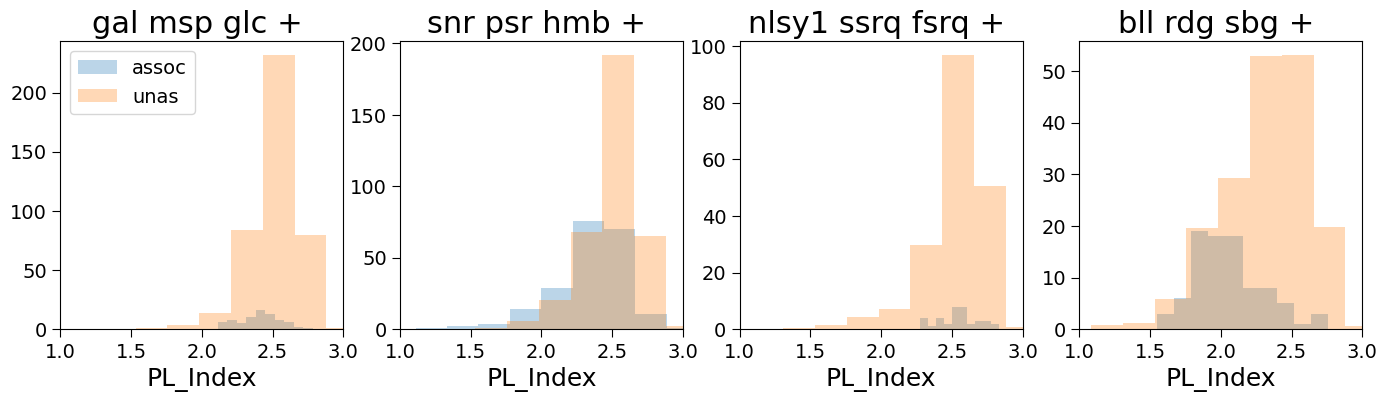

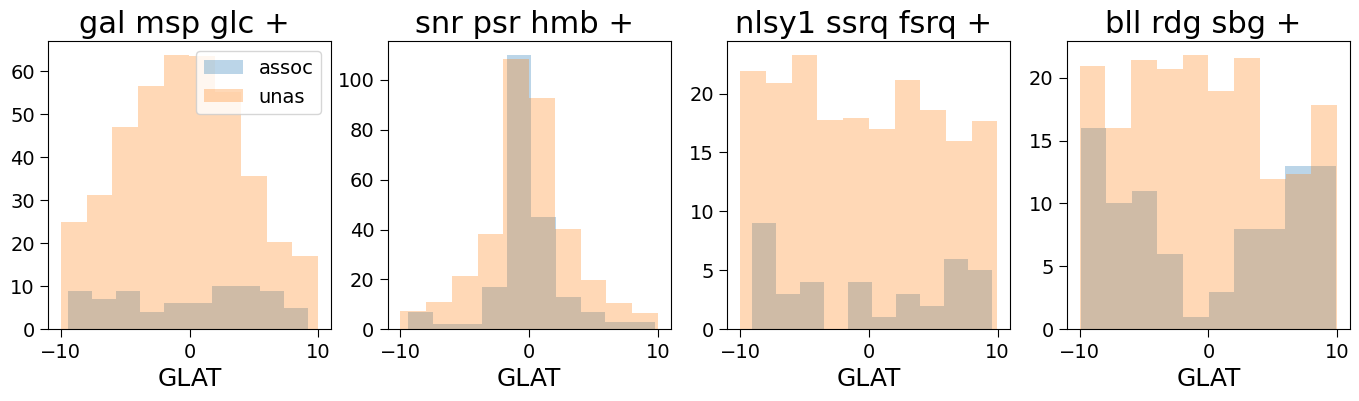

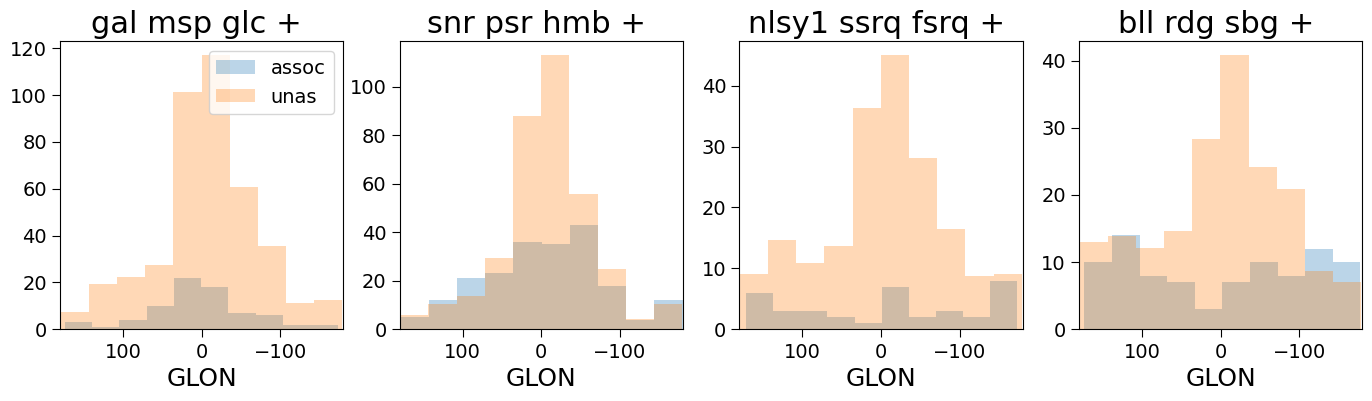

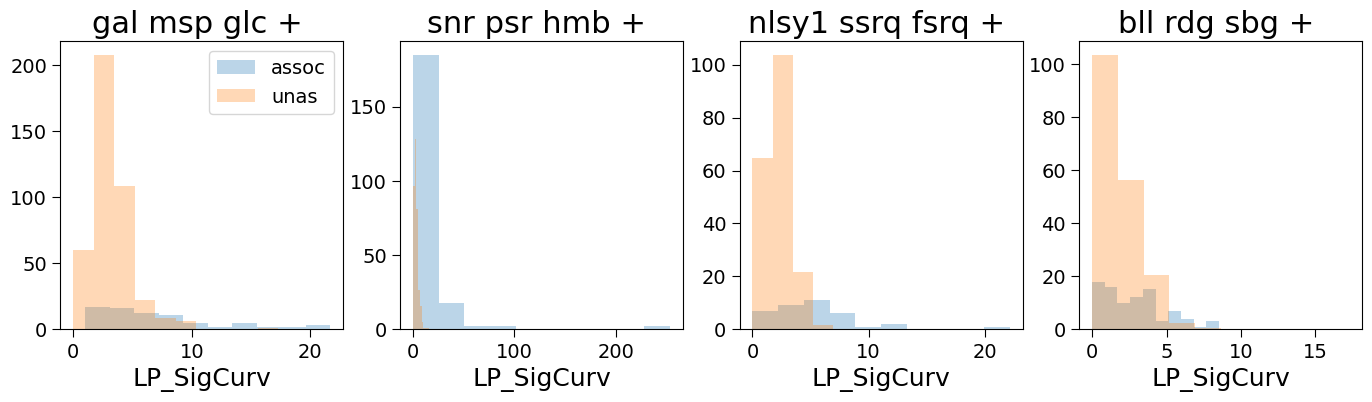

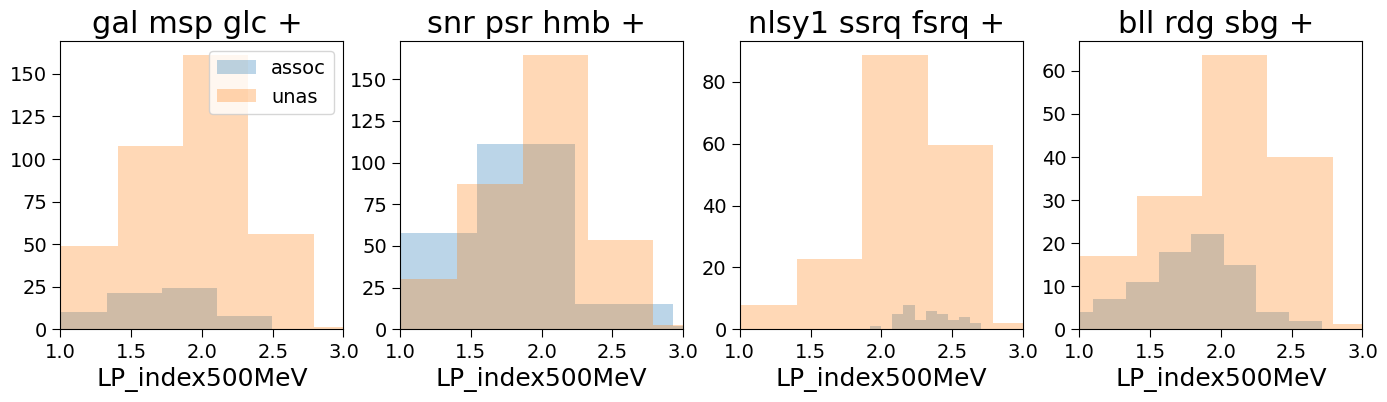

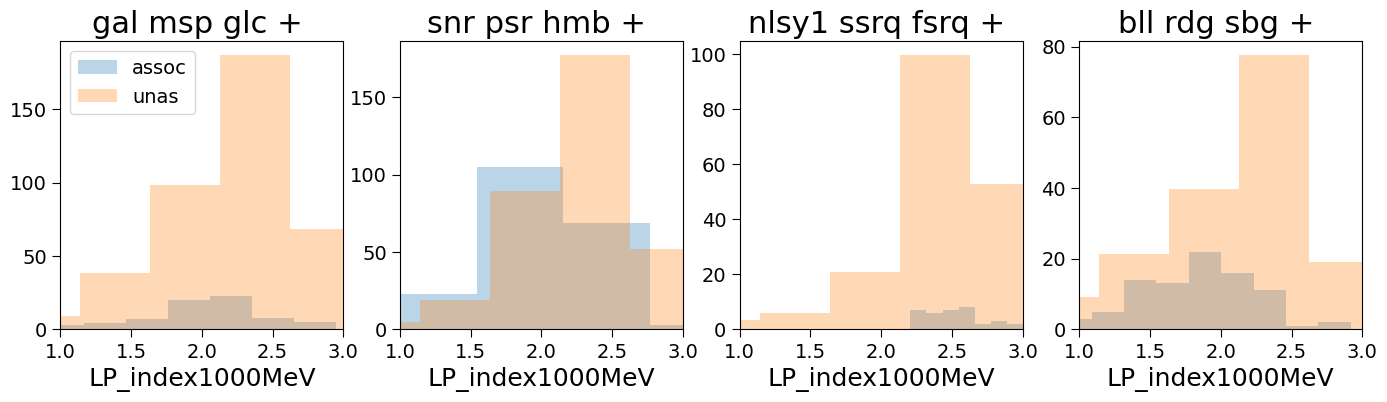

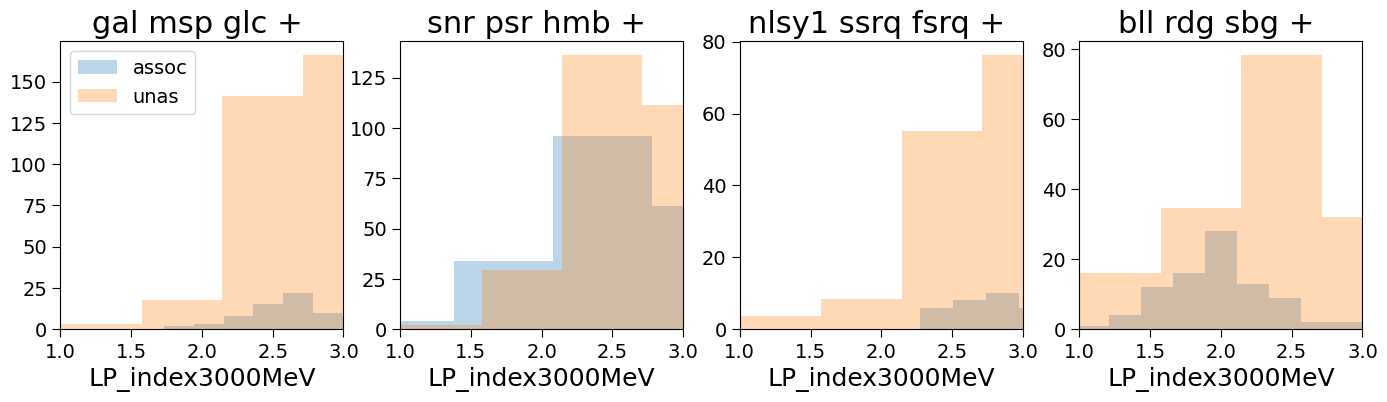

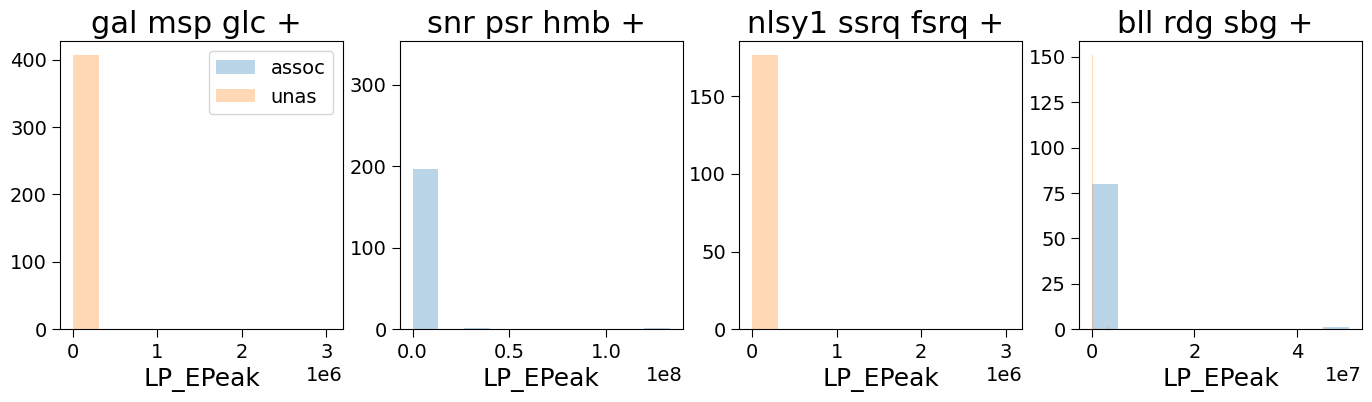

In [431]:
nrows = 1
ncols = ncls_plot
fig_height = 2 * nrows + 2   # height in inches
fig_width = 3 * ncols + 2  # width in inches

fig_size =  [fig_width, fig_height]
pyplot.rcParams['figure.figsize'] =  fig_size
#pyplot.rcParams['axes.titlesize'] =  18
pyplot.rcParams['figure.subplot.bottom'] = 0.18
pyplot.rcParams['figure.subplot.left'] = 0.05
pyplot.rcParams['figure.subplot.right'] = 0.98

def process_values(values, name):
    res = values
    if name == 'GLON':
        res -= (res // 180) * 360
    return res
        
#plot_feature = 'GLON'
for plot_feature in plot_features:
    pyplot.figure()
    for ind, cls in enumerate(plot_classes):
        ax = pyplot.subplot(nrows, ncols, ind + 1)

        # associated sources
        cls_mask = util.get_cl_mask(cut_subtree[cls], df_extra, cname=class_clm)
        vals = df_extra[plot_feature][sga_mask & cls_mask]
        vals = process_values(vals, plot_feature)
        if plot_feature == 'GLON':
            pyplot.xlim(180, -180)
        label = ''
        if ind == 0:
            label = 'assoc'
        pyplot.hist(vals, alpha=0.3, label=label)

        # unassociated sources
        vals = df_extra[plot_feature][sgu_mask]
        vals = process_values(vals, plot_feature)
        weights = ysgu[ind_sort[ind]]
        if ind == 0:
            label = 'unas'
        pyplot.hist(vals, weights=weights, alpha=0.3, label=label)

        #title = list2label(cut_subtree[cls])
        title = list2label(cut_subtree[cls], nsrc_dict, ncl=3, max_only=True)

        pyplot.title(title)
        pyplot.xlabel(plot_feature)
        if ind == 0:
            pyplot.legend()
        if plot_feature.find('LP_index') > -1 or plot_feature == 'PL_Index':
            pyplot.xlim(1., 3.)

    if save_plots and 0:
        fn = '%s/hist_%s_%s.pdf' % (plots_folder, plot_feature, descr_str)
        print('save figure to file: %s' % (fn))
        pyplot.savefig(fn)
        fn = fn.replace('.pdf', '.png')
        pyplot.savefig(fn)


In [432]:
i_out = 0
cls_out = cut_subtree[clf.classes_[i_out]]
label = list2label(cls_out, nsrc_dict, ncl=2, max_only=True)

if 0:
    for i in ind_sort:  
        if 'msp' in cut_subtree[clf.classes_[i]]:
            i_msp = i
            cls_msp = clf.classes_[i]
            break
        msp_mask = util.get_cl_mask(cut_subtree[cls_msp], xdf, cname=class_clm)
else:
    cls_mask = util.get_cl_mask(cls_out, xdf, cname=class_clm)
    
thres = 0.5
sgu_out_mask = ysgu[i_out] > thres
#print(sum(sgu_out_mask), len(sgu_out_mask))
#print(sum(cls_mask), len(cls_mask))
print(cls_out)

['agn', 'sey', 'bll', 'rdg', 'sbg']


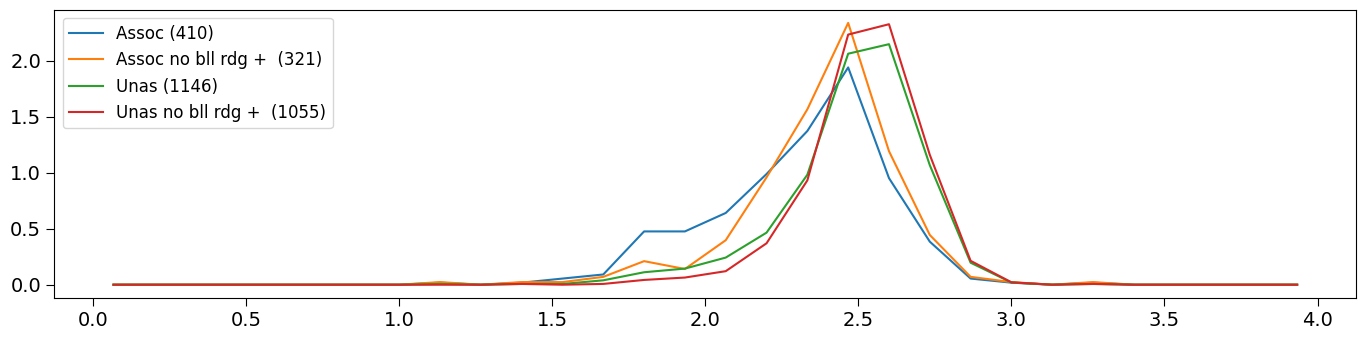

In [433]:
plot_feature = 'PL_Index'
#plot_feature = 'LP_index1000MeV'
density = True
vmin = 0.
vmax = 4.
nbins = 30
bins = np.linspace(vmin, vmax, nbins + 1)
xs = (bins[1:] + bins[:-1]) / 2.
vals = df_extra[plot_feature]
vmask = (vals > vmin) & (vals < vmax)
vdict = {}
vdict['Assoc'] = vals[sga_mask & vmask]
#vdict['Assoc no msp'] = vals[sga_mask & vmask & ~msp_mask]
vdict['Assoc no ' + label] = vals[sga_mask & vmask & ~cls_mask]
vdict['Unas'] = vals[sgu_mask & vmask]

vals_no_msp = vals[sgu_mask][~sgu_out_mask]
vmask_no_msp = (vals_no_msp > vmin) & (vals_no_msp < vmax)
vals_no_msp = vals_no_msp[vmask_no_msp]

vdict['Unas no ' + label] = vals_no_msp

vals_msp = vals[sgu_mask][sgu_out_mask]
vmask_msp = (vals_msp > vmin) & (vals_msp < vmax)
vals_msp = vals_msp[vmask_msp]
#vdict['Unas ' + label] = vals_msp

mean_std_dict = {'mean':{}, 'std':{}}
for key, vals in vdict.items():
    mean_std_dict['mean'][key] = np.mean(vals)
    mean_std_dict['std'][key] = np.std(vals)

pyplot.figure()
for key, vals in vdict.items():
    ys = np.histogram(vals, bins=bins, density=density)[0]
    pyplot.plot(xs, ys, label=key + ' (%i)' % len(vals))
pyplot.legend(loc='upper left', fontsize=12)

In [434]:
mean_std_dict

{'mean': {'Assoc': 2.3115642765673194,
  'Assoc no bll rdg + ': 2.38207445077807,
  'Unas': 2.4813752602948362,
  'Unas no bll rdg + ': 2.516883161056663},
 'std': {'Assoc': 0.2774462166717703,
  'Assoc no bll rdg + ': 0.24297465822245604,
  'Unas': 0.2228475522029494,
  'Unas no bll rdg + ': 0.1818371861551794}}